# May 26

## Large model 1 shot

In [2]:
import pickle 
from glob import glob 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import utils
from collections import defaultdict
import gpt

utils.set_plot_style()




/tmp/ipykernel_1451988/1502289027.py:3: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [3]:
folders = glob("/scratch/qanguyen/gautam/cache/memo_may25_zipf_onelayerattention_large_noresample/*")
# folders = glob("/scratch/qanguyen/gautam/cache/memo_nov10_zipf_gpt2_vary_num_hidden_features_num_heads_doresample/*")
df = defaultdict(list)
for folder in folders:
    pkl = glob(f"{folder}/*")
    run_name = [p for p in pkl if ("model_iter" not in p) and ("sequences" not in p)][0].split("/")[-1] 
    print("run_name", run_name)
    fname = f"{folder}/{run_name}"
    print("fname", fname)
    with open(fname, "rb") as f:
        data = utils.CPU_Unpickler(f).load()
    if "logs" not in data:
        continue
    get_model = lambda: gpt.OneLayerAttention(data["args"]["len_context"], 
                                  data["args"]["num_heads"], 
                                  data["args"]["num_hidden_features"], 
                                  data["args"]["vocab_size"], 
                                  data["args"]["num_mlp_layers"],
                                  is_initialize_attention_weights_to_zero=data["args"]["is_initialize_attention_weights_to_zero"],
                                  ) 
    model = get_model() 
    num_parameters = sum(p.numel() for k, p in model.state_dict().items())
    print("len(data['logs'])", len(data["logs"]), "key", data["logs"][0].keys(), "arch", data["args"]["arch"], "num_parameters", num_parameters, "num_layers", data["args"]["num_layers"], "num_heads", data["args"]["num_heads"], "num_hidden_features", data["args"]["num_hidden_features"])
    # if num_parameters > 1e6 and data["logs"][-1]["train_loss"] > 0.3:
    #     continue
    # if num_parameters > 7e7:
    #     continue
    # if len(data["logs"]) < 10:
    #     continue
    num_hidden_features = data["args"]["num_hidden_features"]
    num_heads = data["args"]["num_heads"] 
    num_appearances_at_39 = None
    for l in data["logs"]:
        num_appearances = l["num_apppearances"][::10]
        
        test_metrics = l["test_metrics"]
        sequence_ranks = test_metrics["sequence_rank"] * 10 
        print("len(sequence_ranks)", len(sequence_ranks))
        accuracy = test_metrics["accuracy"] 
        # if num_appearances_at_39 is not None:
            # num_appearances -= num_appearances_at_39
        df["num_appearances"].extend(num_appearances)
        df["sequence_rank"].extend(sequence_ranks)
        df["accuracy"].extend(accuracy)
        df["num_parameters"].extend([ num_parameters ] * len(num_appearances))
        df["epoch"].extend([l["epoch"]] * len(num_appearances))  
        df["switch_number"].extend([int (1)] * len(num_appearances))   

run_name memo_may25_zipf_onelayerattention_large_noresample_transformer_K_500000_L_100_hidden_256_nheads_16_nlayers_12_1779798119.8600204.pkl
fname /scratch/qanguyen/gautam/cache/memo_may25_zipf_onelayerattention_large_noresample/memo_may25_zipf_onelayerattention_large_noresample_transformer_K_500000_L_100_hidden_256_nheads_16_nlayers_12_1779798119.8600204/memo_may25_zipf_onelayerattention_large_noresample_transformer_K_500000_L_100_hidden_256_nheads_16_nlayers_12_1779798119.8600204.pkl
len(data['logs']) 300 key dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'test_metrics']) arch OneLayerAttention num_parameters 101130242 num_layers 12 num_heads 16 num_hidden_features 256
len(sequence_ranks) 50000
len(sequence_ranks) 50000
len(sequence_ranks) 50000
len(sequence_ranks) 50000
len(sequence_ranks) 50000
len(sequence_ranks) 50000
len(sequence_ranks) 50000
len(sequence_ranks) 50000
len(sequence_ranks) 50000
len(sequence_ranks) 50000
len(sequ

In [ ]:
THRESHOLD = 0.9
_df = pd.DataFrame(df)
cols = ['num_appearances', 'sequence_rank', 'accuracy', 'num_parameters', 'epoch', 'num_appearances_at_saturation']
results = []
df_capacity = defaultdict(list)
for switch_number in _df["switch_number"].unique():
    for num_parameter in _df["num_parameters"].unique():
        # Filter by parameter count
        subdf = _df[np.abs(_df["num_parameters"] - num_parameter) < 1e-2].copy()
        subdf = subdf[subdf["switch_number"] == switch_number]
        # display(subdf)
        
        # 1. Identify which ranks ever reached the threshold
        ranks_that_met_90 = subdf.loc[subdf["accuracy"] > THRESHOLD, "sequence_rank"].unique()
        
        # 2. Extract rows for ranks that met 90% (get the MIN epoch where accuracy > 0.9)
        df_met = (
            subdf[(subdf["sequence_rank"].isin(ranks_that_met_90)) & (subdf["accuracy"] > THRESHOLD)]
            .sort_values("epoch", ascending=True)
            .drop_duplicates("sequence_rank")
        )
        # df_met["num_appearances_at_saturation"] = df_met["num_appearances"]
        assert "switch_number" in df_met, "df_met doesn't have switch_number"
        df_capacity["num_parameters"].extend([num_parameter])
        df_capacity["max_rank_at_saturation"].extend([df_met["sequence_rank"].max()])
        # display("num_parameter", num_parameter, "df_met", df_met)
        # 3. Extract rows for ranks that NEVER met 90% (get the MAX epoch available)
        # df_never_met = (
        #     subdf[~subdf["sequence_rank"].isin(ranks_that_met_90)]
        #     .sort_values("epoch", ascending=False)
        #     .drop_duplicates("sequence_rank")
        # )
        # df_never_met["num_appearances_at_saturation"] = 1e5
        # 4. Combine and filter for requested columns
        result_epochs = (
            pd.concat([df_met])
            .sort_values("sequence_rank")
        )
        results.append(result_epochs)

In [ ]:
results = pd.concat(results)
display(results)
_df = pd.DataFrame(df)
display(_df)


,num_appearances,sequence_rank,accuracy,num_parameters,epoch,switch_number
50000,18736.0,0,1.000000,101130242,1,1
150001,5111.0,10,0.969697,101130242,3,1
250002,4426.0,20,0.939394,101130242,5,1
300003,3663.0,30,0.969697,101130242,6,1
300004,2703.0,40,0.949495,101130242,6,1
...,...,...,...,...,...,...
64102784,62.0,27840,0.909091,88911362,82,1
63452885,57.0,28850,0.929293,88911362,69,1
63654354,38.0,43540,0.909091,88911362,73,1
61054363,9.0,43630,0.919192,88911362,21,1


,num_appearances,sequence_rank,accuracy,num_parameters,epoch,switch_number
0,0.0,0,0.525253,101130242,0,1
1,0.0,10,0.525253,101130242,0,1
2,0.0,20,0.454545,101130242,0,1
3,0.0,30,0.494949,101130242,0,1
4,0.0,40,0.535354,101130242,0,1
...,...,...,...,...,...,...
67549995,10.0,499950,0.484848,88911362,150,1
67549996,3.0,499960,0.454545,88911362,150,1
67549997,9.0,499970,0.464646,88911362,150,1
67549998,6.0,499980,0.545455,88911362,150,1


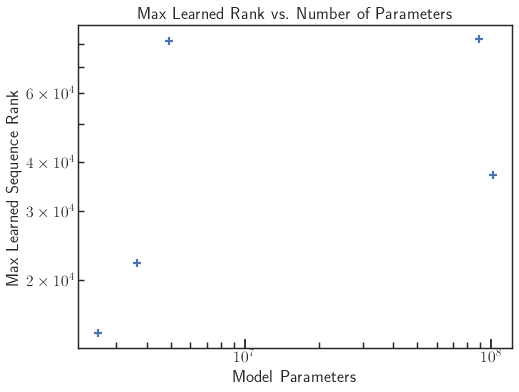

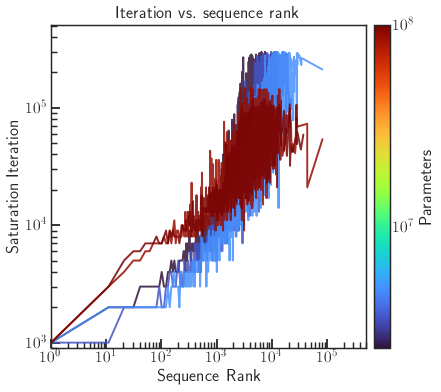

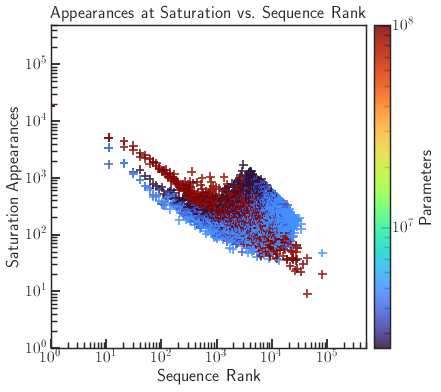

In [ ]:
# plot the max rank at saturation vs num parameters
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
plt.scatter(df_capacity["num_parameters"], df_capacity["max_rank_at_saturation"],
    s=70, marker="+")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Model Parameters")
plt.ylabel("Max Learned Sequence Rank")
plt.title("Max Learned Rank vs. Number of Parameters")
plt.show()

from matplotlib.colors import LogNorm
import matplotlib.ticker as mticker

# plot the saturation time vs sequence rank
def compute_saturation_time(row):
    time = row["epoch"]
    if row["switch_number"] == 1:
        return time * 1000
    else:
        return (time - (row["switch_number"] - 1) * 40) * 1000

results["iters"] = results.apply(compute_saturation_time, axis=1)
results["sequence_rank_plus_one"] = results["sequence_rank"] + 1

fig, axs = plt.subplots(1, 1, figsize=(7, 6))
axs = [axs]

plot_results = results[results["switch_number"].isin(range(1, 2))].copy()
plot_results["num_parameters"] = pd.to_numeric(plot_results["num_parameters"])
plot_results["sequence_rank_plus_one"] = pd.to_numeric(plot_results["sequence_rank_plus_one"])

norm = LogNorm(
    vmin=plot_results["num_parameters"].min(),
    vmax=plot_results["num_parameters"].max(),
)

for i, switch_number in enumerate(range(1, 2)):
    subresults = plot_results[plot_results["switch_number"] == switch_number].copy()
    subresults = subresults.sort_values(["num_parameters", "sequence_rank_plus_one"])

    sns.lineplot(
        data=subresults,
        x="sequence_rank_plus_one",
        y="iters",
        hue="num_parameters",
        palette="turbo",
        hue_norm=norm,
        linewidth=2.0,
        alpha=0.85,
        legend=False,
        ax=axs[i]
    )

    axs[i].set_title("Iteration vs. sequence rank")
    axs[i].set_xscale("log")
    axs[i].set_xlim(1, 510000)
    axs[i].set_ylim(900, 510000)
    axs[i].set_yscale("log")
    axs[i].set_xlabel("Sequence Rank")
    axs[i].set_ylabel("Saturation Iteration")

sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs[0], pad=0.02)
cbar.set_label("Parameters")
cbar.formatter = mticker.LogFormatterSciNotation()
cbar.update_ticks()
 
plt.show()

fig, axs = plt.subplots(1, 1, figsize=(7, 6))
axs = [axs]

plot_results = results[results["switch_number"].isin(range(1, 2))].copy()
plot_results["num_parameters"] = pd.to_numeric(plot_results["num_parameters"])
plot_results["sequence_rank_plus_one"] = pd.to_numeric(plot_results["sequence_rank_plus_one"])

norm = LogNorm(
    vmin=plot_results["num_parameters"].min(),
    vmax=plot_results["num_parameters"].max(),
)

sc = None
for i, switch_number in enumerate(range(1, 2)):
    subresults = plot_results[plot_results["switch_number"] == switch_number].copy()
    subresults = subresults.sort_values(
        ["sequence_rank_plus_one", "num_parameters"],
        ignore_index=True,
    )

    sc = axs[i].scatter(
        subresults["sequence_rank_plus_one"],
        subresults["num_appearances"],
        c=subresults["num_parameters"],
        cmap="turbo",
        norm=norm,
        linewidths=1.8,
        alpha=0.85,
        marker="+",
    )

    axs[i].set_title("Appearances at Saturation vs. Sequence Rank")
    axs[i].set_xscale("log")
    axs[i].set_xlim(1, 510000)
    axs[i].set_ylim(1, 500000)
    axs[i].set_yscale("log")
    axs[i].set_xlabel("Sequence Rank")
    axs[i].set_ylabel("Saturation Appearances")

cbar = fig.colorbar(sc, ax=axs[0], pad=0.02)
cbar.set_label("Parameters")
cbar.formatter = mticker.LogFormatterSciNotation()
cbar.update_ticks()
 
plt.show()
